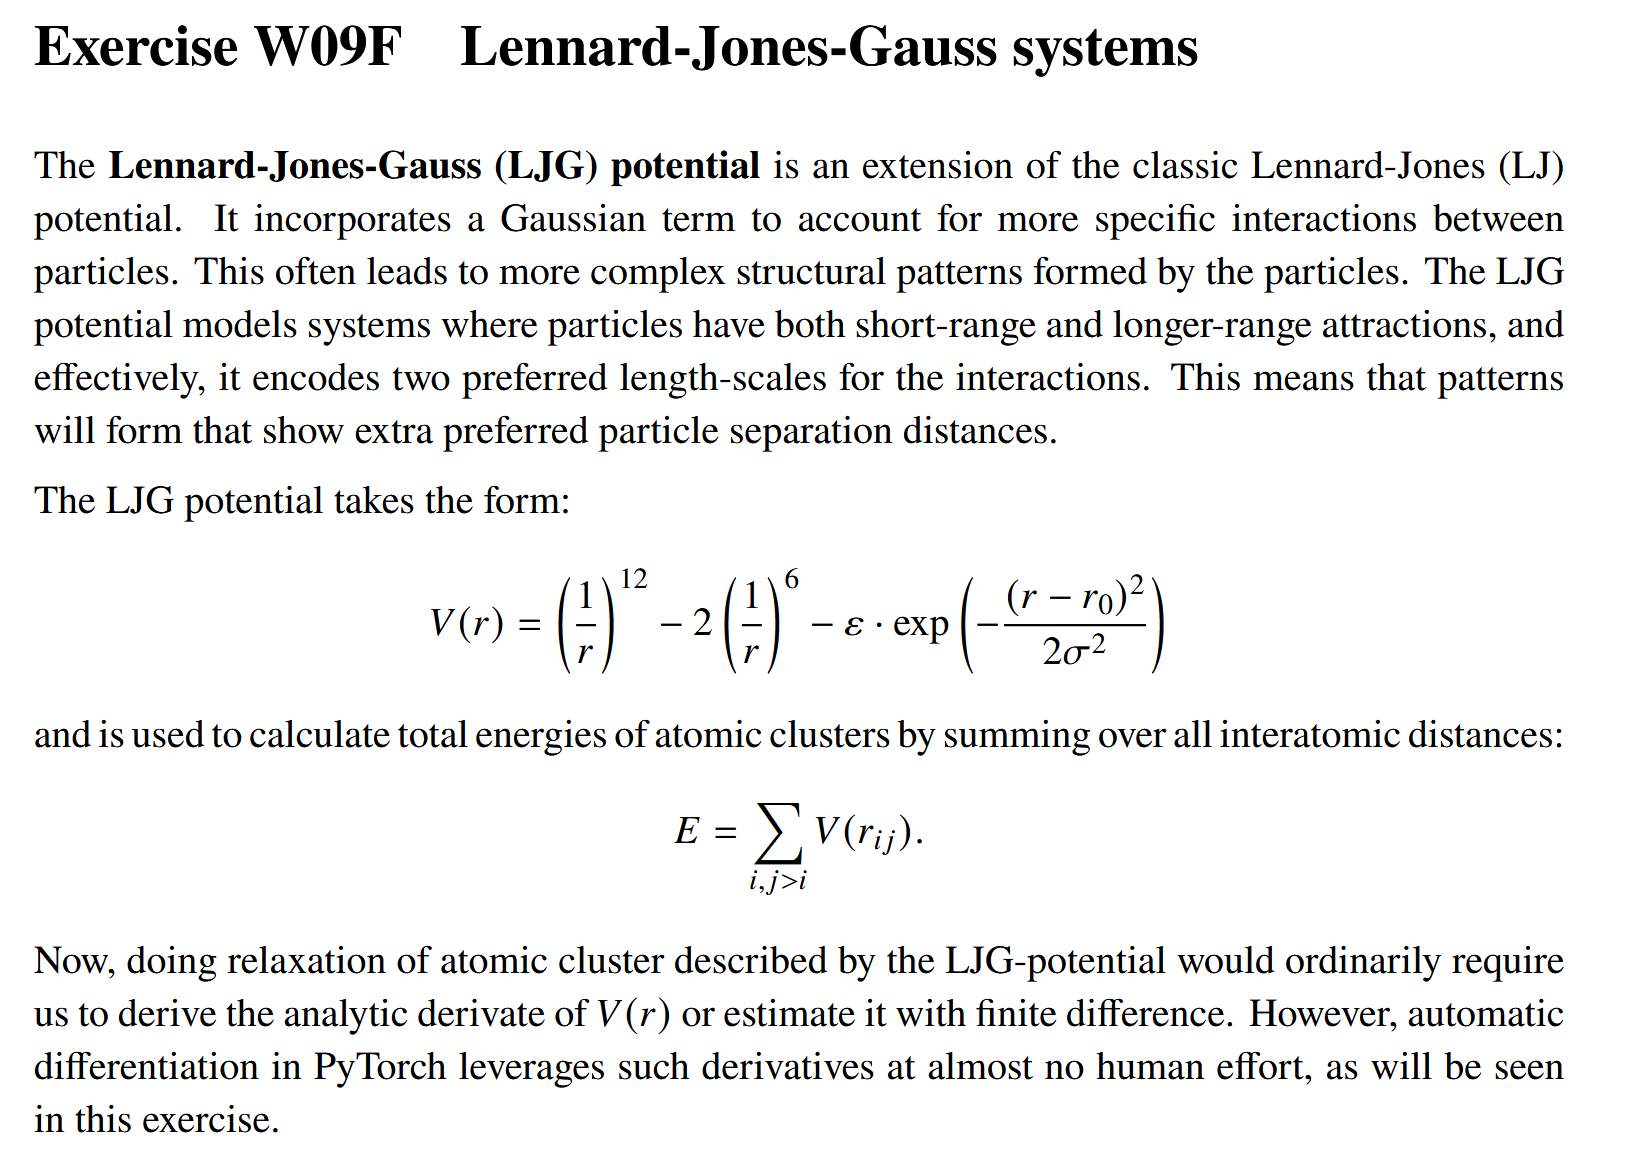

In [39]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np

class LennardJonesGauss:
    def __init__(self, eps=1.0, sigma_sq=0.02, r0=1.7):
        self.eps = eps
        self.s2 = sigma_sq
        self.r0 = r0

    def V(self, r):
        return r**(-12) - 2*r**(-6) - self.eps * torch.exp(-(r-self.r0)**2 / (2*self.s2))

class LJGSystem(nn.Module):
    def __init__(self, *args, calc, Natoms, **kwargs):
        super().__init__(*args, **kwargs)
        self.calc = calc

        self.pos = nn.Parameter(torch.rand((Natoms, 2)) * 6.0)

    def forward(self):
        distances = torch.pdist(self.pos)
        return torch.sum(self.calc.V(distances))

    def draw(self, ax):
        coords = self.pos.detach().numpy()
        ax.scatter(coords[:, 0], coords[:, 1], s=200, c='blue', alpha=0.5)
        ax.set_title(f'E = {self.forward():.2f}')
        ax.set_xlabel("X coordinate")
        ax.set_ylabel("Y coordinate")
        ax.grid(True, linestyle='--', alpha=0.5)
        ax.axis('equal') 
        

pos =  [[4.065, 5.93 ],
        [3.211, 5.465],
        [5.711, 4.9 ],
        [6.567, 5.374],
        [4.113, 6.903],
        [5.741, 5.879],
        [5.662, 3.924],
        [4.893, 5.411],
        [4.844, 4.443],
        [4.036, 4.953],
        [6.539, 4.384],
        [4.931, 6.382]]


calc = LennardJonesGauss()
dist = torch.pdist(torch.tensor(pos))
print(f'potential = {torch.sum(calc.V(dist))}')

potential = -40.66716384887695


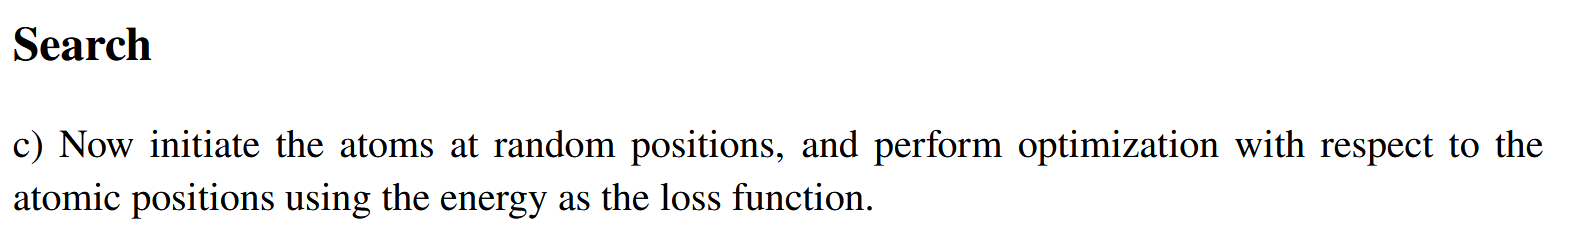
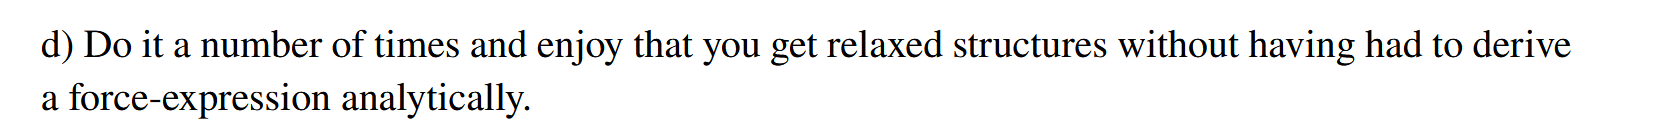

potential = -39.75


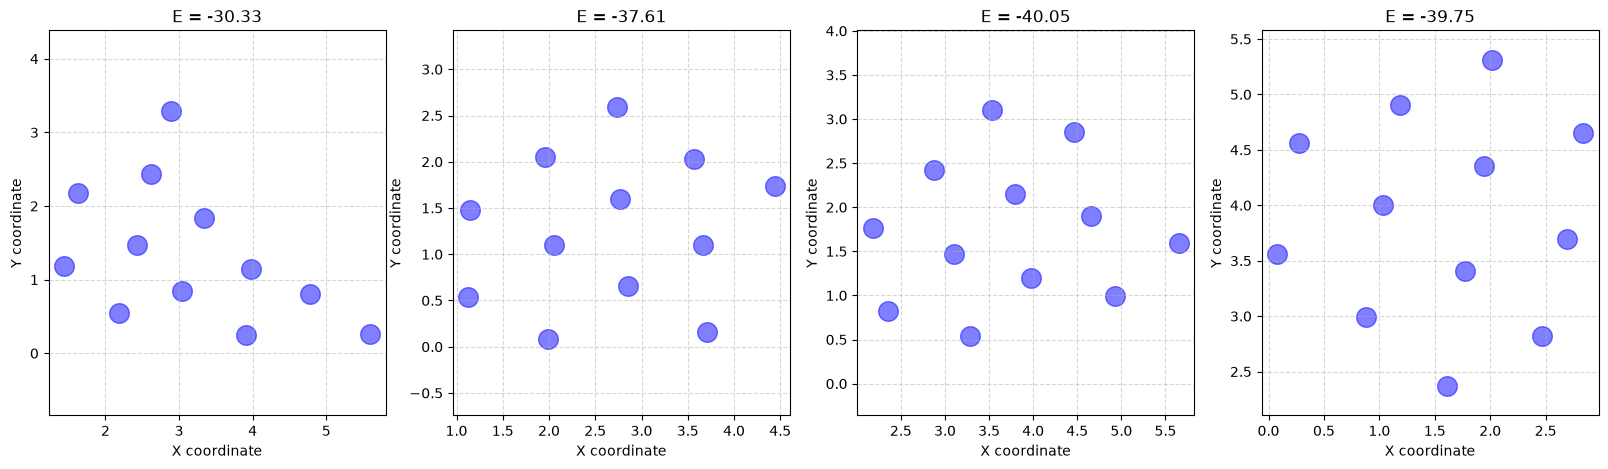

In [51]:
model = LJGSystem(calc=calc, Natoms=12)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

optimizer = optim.Adam(model.parameters(), lr=0.2)

epochs = 4000
i = 0
for epoch in range(epochs):
    optimizer.zero_grad()
    
    energy = model()
    energy.backward()
    nn.utils.clip_grad_value_(model.parameters(), clip_value=0.5)
    optimizer.step()

    if (epoch + 1) % 1000 == 0:
        model.draw(axes[i])
        i += 1


print(f'potential = {model().item():.2f}')
